# 1. Introdução

Até aqui, vimos diversas estratégias para obter uma solução regularizada para um problema inverso. Em suma, nossa missão foi tentar equilibrar as normas $\ell_2$ do **resíduo** e da **solução** a fim de encontrar um parâmetro de regularização ótimo ou um ponto ótimo de parada para os solvers iterativos. Associado à norma $\ell_2$ está o fato de que as soluções encontradas são, de alguma forma, suaves — o que é uma pressuposição válida em muitos casos de interesse. Mas e se este não for o caso? E se, no espaço de solução, o sinal do termo-fonte for composto apenas por alguns componentes não nulos? 

Nesta aula, vamos tentar ir um pouco além da norma $\ell_2$, introduzindo normas e métodos de regularização que promovam uma solução essencialmente **esparsa**.

## 1.1. O problema direto que analisaremos

O problema de **análise de campos sonoros bidimensionais** é um problema direto no qual a pressão sonora medida resulta da superposição de ondas planas propagantes. O campo sonoro, em uma determinada frequência angular, $\omega$ [rad/s], e posição $\mathbf{r}_{\text{m}} = (x_{\text{m}}, z_{\text{m}})$ [m], é descrito por

\begin{equation}
    \tilde{p}(\mathbf{r}_{\text{m}}, \omega)
    = \sum\limits_{i=1}^{N} \tilde{x}_i \exp(\text{-j} \mathbf{k}_i \cdot \mathbf{r}_{\text{m}}),
\tag{1}
\end{equation}

em que $\mathbf{k}_i = (k_{x_i}, k_{z_i})$ é o vetor número de onda da $i$-ésima onda plana, cuja norma é $\|\mathbf{k}_i\|_2 = \frac{\omega}{c_0}=k_0$, e $N$ representa o número de ondas planas que compõem o campo sonoro. Observe que podemos ter tanto um pequeno número de ondas planas (solução **esparsa**) quanto uma distribuição aproximadamente contínua de ondas planas (solução **suave**).

O problema está restrito a ondas planas propagantes, que satisfazem a condição:

\begin{equation}
    \|\mathbf{k}_i\|_2^2 = k_{x}^2 + k_{z}^2 = k_0^2.
\tag{2}
\end{equation}

Nosso objetivo é duplo:

- Estimar as **amplitudes complexas** das ondas planas candidatas a partir de medições espaciais da **pressão sonora complexa**;
- Reconstruir o campo sonoro em posições nas quais não foram realizadas medições (veja o esquema da Fig. 1).

Observe que as medições são realizadas no **domínio espacial**, enquanto a estimativa das amplitudes das ondas planas ocorre no **domínio dos números de onda**.

<figure style="text-align: center;">
    <img src="\..\figs\sf2D_scheme.svg" width="500" alt="Representação conceitual do campo sonoro bidimensional.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 1: Representação esquemática do problema de análise de campos sonoros bidimensionais.
    </figcaption>
</figure>

A biblioteca `PyRegTools` permite configurar o problema `SoundField2D` por meio do módulo `toyproblems`. Com essa classe, podemos fornecer informações sobre a medição simulada, como as coordenadas dos microfones, a velocidade do som ($c_0$ [m/s]) e a frequência de análise ($f$ [Hz]).

Também podemos calcular o campo sonoro medido sem ruído (`b_true`), adicionar ruído às medições (`b_noisy`) e construir a matriz de sensibilidade (`A`) a partir de ondas planas candidatas utilizadas para representar o campo sonoro.

Uma observação importante é que as ondas planas são idealizações matemáticas. Embora a superposição de ondas planas possa descrever um campo sonoro localmente, não é possível observar essas ondas individualmente em todo o espaço. Em certo sentido, as ondas planas são construções matemáticas capazes de representar uma realidade física local.

Por esse motivo, em problemas físicos reais, geralmente não conhecemos os verdadeiros coeficientes das ondas planas que compõem o campo sonoro. Essa é a razão pela qual a variável `x_true` não foi incorporada à classe `SoundField2D`. Optamos por defini-la separadamente, para fins de demonstração e para manter essa distinção conceitual clara ao longo dos exemplos.

Vamos investigar esse problema e sua correspondente formulação inversa.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pyregtools
from pyregtools.toyproblems.sound_field_2D import SoundField2D
from pyregtools import regsolvers
from pyregtools import iterativesolvers
from pyregtools import regchoice

In [2]:
# Helper functions
def plot_in_space(coord, pres = None):
    """ Helper function to plot the microphone array
    """
    if pres is None:
        plt.figure(figsize=(4, 4))
        plt.scatter(coord[:,0], coord[:,1], c = 'b', s=10, marker="x", alpha = 0.6)
        plt.grid(linestyle = '--')
    else:
        min_val, max_val = np.real(pres).min(), np.real(pres).max()
        range_c = np.amax(np.abs([min_val, max_val]))
        plt.figure(figsize=(5, 4))
        scatter = plt.scatter(coord[:,0], coord[:,1], c=np.real(pres),
                              cmap='bwr', s=30, edgecolor='none', vmin = -range_c, vmax = range_c)
        cbar = plt.colorbar(scatter)
        cbar.set_label(r'$\mathcal{R}\left\{p\right\}$', fontsize=10)
    plt.xlabel(r"$x$ [m]")
    plt.ylabel(r"$z$ [m]")
    plt.xlim((-0.5,0.5))
    plt.ylim((-0.5,0.5))
    plt.title(r'$M = {}$ microphones.'.format(coord.shape[0]))
    plt.tight_layout()

def compare_sf(figsize, coord, pres_ref, pres_recon):
    """Compare reference, reconstructed, and error sound fields."""

    nmse = pyregtools.utils.nmse_fun(x_ref=pres_ref, x_meas=pres_recon)

    error = (np.abs(np.real(pres_ref) - np.real(pres_recon)))#/np.abs(np.real(pres_ref))
    range_c = np.max(np.abs(np.real(pres_ref)))

    # Three equal-width plots, plus a row for colorbars
    fig = plt.figure(figsize=figsize, layout="constrained")
    gs = fig.add_gridspec(2, 3,
        height_ratios=[1, 0.05],
        hspace=0.12,
        wspace=0.10)
    ax = [fig.add_subplot(gs[0, i]) for i in range(3)]

    # Reference field
    scatter = ax[0].scatter(coord[:, 0], coord[:, 1], c=np.real(pres_ref), cmap="bwr", s=30, edgecolor="none",
        vmin=-range_c, vmax=range_c)
    ax[0].set_title("True", fontsize=10)

    # Reconstructed field
    ax[1].scatter(coord[:, 0], coord[:, 1], c=np.real(pres_recon), cmap="bwr", s=30, edgecolor="none",
        vmin=-range_c, vmax=range_c)
    ax[1].set_title(f"Recon (NMSE = {nmse:.2e})", fontsize=10)

    # Absolute error
    scatter_err = ax[2].scatter(coord[:, 0], coord[:, 1], c=error, cmap="Greys",
        s=30, edgecolor="none", vmin=0, vmax=np.real(pres_ref).max())#
    ax[2].scatter(problem.coord[:, 0], problem.coord[:, 1],
        c="b", s=10, alpha=0.45, marker="x")
    ax[2].set_title("Absolute error", fontsize=10)

    # Equal dimensions and limits
    for a in ax:
        a.set_xlabel(r"$x$ [m]")
        a.set_xlim(-0.5, 0.5)
        a.set_ylim(-0.5, 0.5)
        a.set_aspect("equal", adjustable="box")

    ax[0].set_ylabel(r"$z$ [m]")

    # Colorbar spanning first two plots
    cax1 = fig.add_subplot(gs[1, 0:2])
    cbar1 = fig.colorbar(scatter, cax=cax1, orientation="horizontal")
    cbar1.set_label(r"$\mathcal{R}\{p\}$", fontsize=10)

    # Colorbar below error plot
    cax2 = fig.add_subplot(gs[1, 2])
    cbar2 = fig.colorbar(scatter_err, cax=cax2, orientation="horizontal")
    cbar2.set_label(r"$|\Delta \mathcal{R}\{p\}|$", fontsize=10)

# 2. Problema direto e termos de fonte

Vamos instanciar o problema `SoundField2D`, especificando a velocidade do som ($c_0$) e a frequência de análise ($f$).

Também vamos configurar um arranjo regular de microfones, distribuídos em uma região retangular centrada em $(0,0)$. As dimensões do arranjo (*aperture*) serão de $x_{\text{len}} \times z_{\text{len}}$. Dentro dessa região, o arranjo realizará medições da pressão sonora em $M = n_x n_z$ posições.

Para configurar esse arranjo, podemos utilizar o método `set_mic_array`.

In [3]:
problem = SoundField2D(c0 = 340, freq = 2000) # instantiate
snr = 30 # Your desired SNR

Shape of the measured coord: (100, 2)


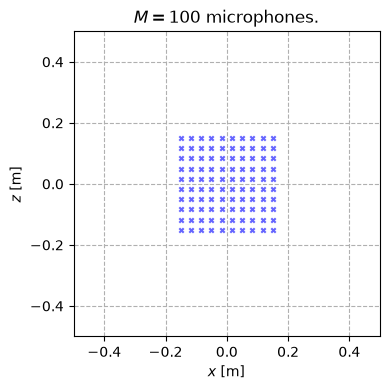

In [4]:
problem.set_mic_array(x_len = 0.3, z_len = 0.3, n_x = 10, n_z = 10)
print("Shape of the measured coord: {}".format(problem.coord.shape))
plot_in_space(problem.coord)

## 2.1. Onda plana única

O método `compute_pres` pode ser utilizado para calcular a pressão sonora de acordo com a Eq. (1). Para isso, basta fornecer ao método os ângulos (em graus) das ondas planas que produziram a medição e suas respectivas amplitudes.

**OBSERVAÇÃO:** Os ângulos das ondas planas são medidos em relação ao eixo $z$, de modo que $0^{\circ}$ corresponde à direção superior do arranjo de microfones, enquanto $180^{\circ}$ corresponde à direção inferior.

Vamos observar como se comporta a parte real do campo de pressão sonora medido ($\mathcal{R}e\{\mathbf{p}\}$) quando a fonte é composta por uma única onda plana.

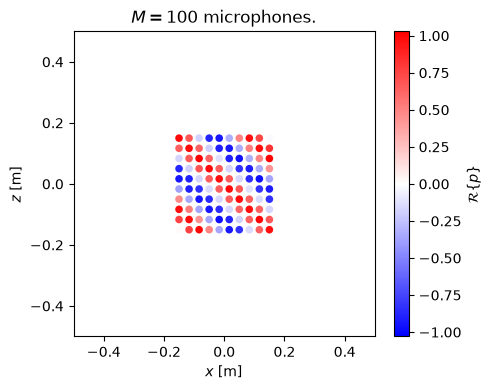

In [5]:
theta_deg = [45]
amps = [1]
# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]

problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
plot_in_space(problem.coord, problem.b_noisy)

## 2.2. Superposição de duas ondas planas

A superposição de duas ondas planas é simples de realizar com o método `compute_pres`. Basta fornecer um *tuple* ou uma lista contendo os ângulos (em graus) e suas respectivas amplitudes (ambas com dois elementos).

Vamos observar como se comporta a parte real do campo de pressão sonora medido ($\mathcal{R}e\{\mathbf{p}\}$) quando resulta da superposição de duas ondas planas.

Observe que o campo sonoro passa a apresentar um padrão mais complexo. Já é bastante difícil identificar as direções de propagação das ondas e suas amplitudes relativas apenas pela observação do campo.

**Observação:** Para adicionar mais ondas planas à superposição, basta acrescentar seus ângulos e amplitudes às tuplas ou listas originais.

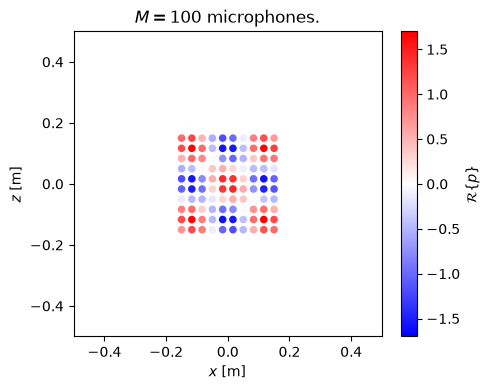

In [6]:
theta_deg = (45, 315)
amps = (1, 0.7)
# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]
x_true[theta_deg_true==theta_deg[1]] = amps[1]

# Forward problem
problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
plot_in_space(problem.coord, problem.b_noisy)

## 2.3. Distribuição suave de ondas planas

O método `smooth_sf` permite calcular o campo sonoro produzido por uma distribuição suave de 360 ondas planas, cujas amplitudes são dadas por

\begin{equation}
\tilde{a}_i = \sin^2(q \theta_i)/360,
\end{equation}

em que $q$ é o fator de modulação das amplitudes e $\theta_i = 2\pi i/N$, com $i=0,\ldots,N-1$.

Vamos observar como se comporta a parte real do campo de pressão sonora medido ($\mathcal{R}e\{\mathbf{p}\}$) quando resulta da superposição de um grande número de ondas planas.

Observe que o campo sonoro apresenta um padrão bastante complexo, o que torna muito difícil identificar as direções de propagação das ondas e suas amplitudes relativas apenas pela observação do campo.

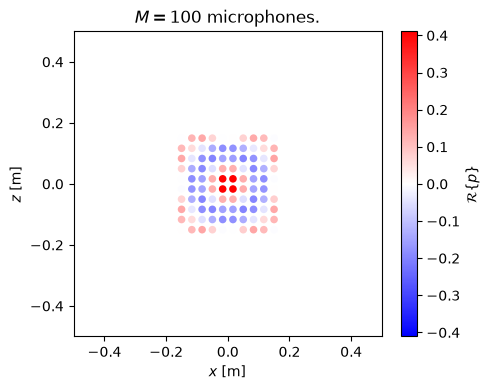

In [7]:
# True source term
factor = 4
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2
x_true /= np.amax(np.abs(x_true))

problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
plot_in_space(problem.coord, problem.b_noisy)

# 3. Problema inverso

Agora podemos formular o problema inverso, estimar as amplitudes das ondas planas e reconstruir o campo sonoro. Começaremos pela análise do campo sonoro produzido por uma distribuição **suave** de ondas planas. Neste caso, esperamos que a solução regularizada de Tikhonov seja uma boa solução.

## 3.1. Formulação do problema inverso

O primeiro passo para formular o problema inverso é determinar o número de ondas planas candidatas cujas amplitudes desejamos estimar ($L$). Em seguida, podemos determinar as coordenadas de $L$ pontos no círculo unitário. Para isso, utilizamos:

\begin{equation}
\theta_{i} = \frac{2 \pi i}{L},
\tag{3}
\end{equation}

em que $i = 0, 1, \ldots, L-1$, e $L$ é o número desejado de ondas planas candidatas.

No domínio do número de onda, $\mathbf{k}_i$, o vetor número de onda de cada onda plana candidata será:

\begin{equation}
\mathbf{k}_{i} = [k_0 \sin(\theta_{i}), k_0 \cos(\theta_{i})],
\tag{4}
\end{equation}

Considerando um total de $L$ ondas planas candidatas, podemos construir uma matriz contendo seus vetores número de onda, com dimensões $L \times 2$.

Cada elemento da matriz de sensibilidade será dado por

\begin{equation}
a_{mi} = \exp(\text{-j} \mathbf{k}_i \cdot \mathbf{r}_{\text{m}}),
\tag{5}
\end{equation}

e o problema inverso resultante será

\begin{equation}
\underbrace{\begin{bmatrix}
\tilde{p}(\mathbf{r}_{0}) \\ \tilde{p}(\mathbf{r}_{1}) \\ \vdots \\ \tilde{p}(\mathbf{r}_{M-1})
\end{bmatrix}}_{\text{medições}} =
\underbrace{\begin{bmatrix}
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{0}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{0}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{0}) \\
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{1}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{1}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{1})\\
\vdots & \vdots & \ddots & \vdots\\
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{M-1}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{M-1}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{M-1})\\
\end{bmatrix}}_{\text{matriz de sensibilidade} \ \in \ \mathbb{C}^{M \times L}}
\underbrace{\begin{bmatrix}
\tilde{x}_0 \\ \tilde{x}_1 \\ \vdots \\ \tilde{x}_{L-1}
\end{bmatrix}}_{\text{incógnitas}}
\tag{6}
\end{equation}

O método `get_sens_mtx` permite calcular essa matriz de sensibilidade para um número desejado de ondas planas candidatas $L$. Observe que a construção dessa matriz de sensibilidade é independente da simulação do problema direto.

Vamos primeiro recalcular o problema direto utilizando o método `smooth_sf`, cujo campo sonoro é produzido por uma distribuição suave de fontes sonoras. Também calcularemos a distribuição dos termos de fonte.

In [9]:
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_array(x_len = 0.3, z_len = 0.3, n_x = 10, n_z = 10)
factor = 4
problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
# source term
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2

#### Podemos formar a matriz de sensibilidade, computar seu SVD e olhar o plot de Picard.

In [10]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
u, s, v = regsolvers.csvd(problem.A)

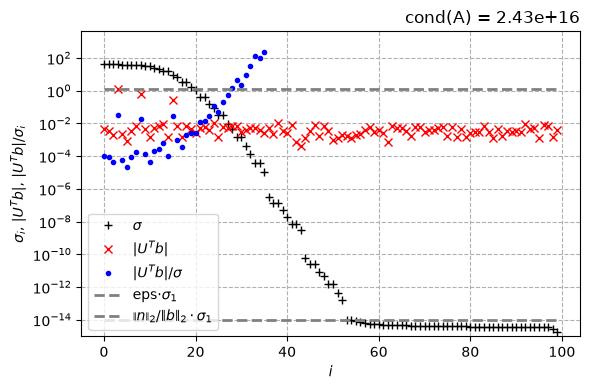

In [12]:
noise_norm = 10**(-snr / 20) * np.linalg.norm(np.abs(problem.b_true))
pyregtools.utils.plot_picard(u, s, problem.b_noisy, noise_norm = noise_norm, figsize = (6,4))

## 3.2. Solução de Tikhonov e escolha do parâmetro ótimo $\lambda$

Vamos utilizar uma solução regularizada baseada na decomposição em valores singulares (SVD) da matriz $\mathbf{A}$. 

A SVD já foi calculada com a função `csvd`. Agora, podemos combiná-la com os dados medidos para escolher o parâmetro de regularização ótimo $\lambda$. Neste caso, utilizaremos o método da curva L.

Com o ótimo valor de $\lambda$, também podemos calcular a solução de Tikhonov a partir da SVD de $\mathbf{A}$ e dos dados contaminados por ruído.

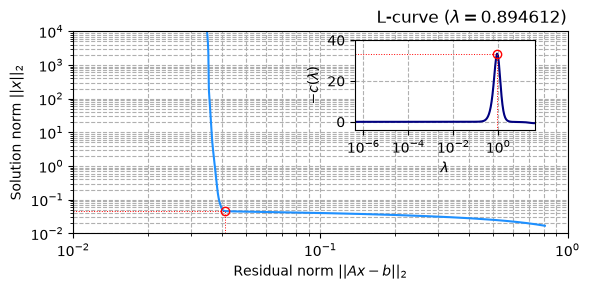

In [13]:
lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method
x_tik = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter

### Visualização da distribuição normalizada de energia

Podemos utilizar a função `plot_solution_field` para visualizar uma versão normalizada do módulo das amplitudes das ondas planas. Essa representação é útil para identificar as direções de onde provém a maior parte da energia do campo sonoro.

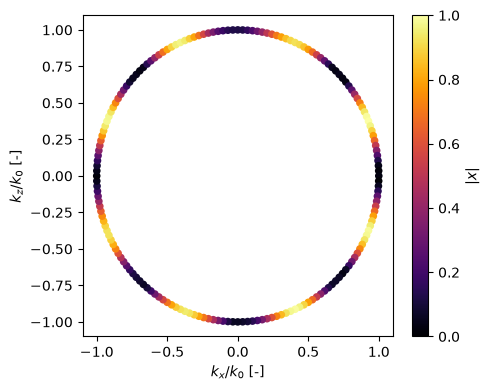

In [14]:
problem.plot_solution_field(x_tik)

# 4. Comparação entre diferentes solucionadores

Após determinar o valor ótimo de $\lambda$, podemos comparar as **amplitudes relativas** das soluções obtidas por diferentes *solvers*. A biblioteca `PyRegTools` disponibiliza diversos *solvers* no módulo `regsolvers`. Vamos comparar:

- Solução por mínimos quadrados;
- Solução de Tikhonov via SVD (já calculada);
- Solução Ridge da biblioteca scikit-learn.

## 4.1. Solução por mínimos quadrados

Este *solver* calcula a solução por mínimos quadrados utilizando a função <a href="https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html" target="_blank">`numpy.linalg.lstsq`</a>.

Essa solução é equivalente à solução de Tikhonov com $\lambda = 0$. Observe que o erro dessa solução é bastante elevado, pois o método dos mínimos quadrados está sujeito ao sobreajuste (*overfitting*) dos dados.

In [15]:
x_ls = regsolvers.least_sq(problem.A, problem.b_noisy)

## 4.2. Regressão Ridge via scikit-learn

Este *solver* calcula a solução utilizando a regressão Ridge da biblioteca scikit-learn (outra denominação para a regularização de Tikhonov), por meio da função <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html" target="_blank">`sklearn.linear_model.Ridge`</a> (**adaptada para matrizes e dados complexos**).

Observe que, na notação utilizada pela regressão Ridge do scikit-learn, o parâmetro de regularização é equivalente a $\lambda^2$.

In [16]:
x_ridge = regsolvers.sklearn_ridge_c(problem.A, problem.b_noisy, lam_l**2) 

## 4.3. Regressão Ridge via cvxpy

Este *solver* calcula a solução utilizando a regressão Ridge (outra denominação para a regularização de Tikhonov), por meio da biblioteca <a href="https://www.cvxpy.org/" target="_blank">`cvxpy`</a>.

Observe que esse *solver* pode ser utilizado com matrizes e dados reais ou complexos. Ele também permite realizar uma regressão Lasso em vez de uma regressão Ridge. Exploraremos a regressão Lasso ao longo deste notebook.

In [17]:
x_cvx = regsolvers.cvx_reg(problem.A, problem.b_noisy, lam_l, is_lasso = False, is_complex = True)

### Comparação entre os *solvers* até aqui

Como esperado, a solução por mínimos quadrados é sensível ao ruído e está sujeita ao sobreajuste (*overfitting*) dos dados.

Além disso, as soluções obtidas pelos demais *solvers* são semelhantes neste caso. As diferenças entre os *solvers* podem depender das características específicas do problema analisado.

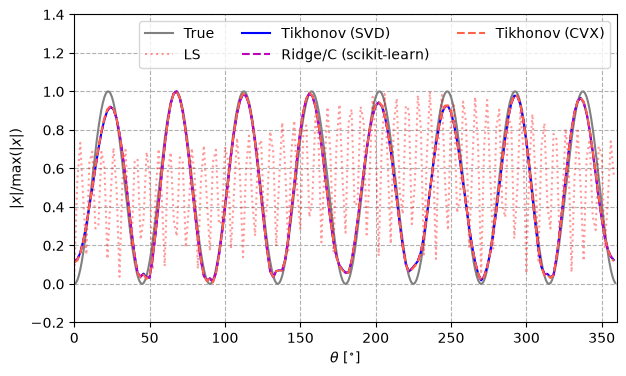

In [19]:
plt.figure(figsize = (7,4))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = "True")
plt.plot(np.rad2deg(theta_dir), np.abs(x_ls)/np.amax(np.abs(x_ls)), 
        ':', color = 'red', alpha = 0.4, label = "LS")
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = "Tikhonov (SVD)")
plt.plot(np.rad2deg(theta_dir), np.abs(x_ridge)/np.amax(np.abs(x_ridge)),
        '--m',label = "Ridge/C (scikit-learn)")
plt.plot(np.rad2deg(theta_dir), np.abs(x_cvx)/np.amax(np.abs(x_cvx)),
        '--', color = 'tomato' ,label = 'Tikhonov (CVX)')
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.4))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## 4.4. Solucionador de mínimos quadrados por gradientes conjugados

No notebook de remoção de desfoque de imagens, estudamos alguns *solvers* iterativos, incluindo o método de mínimos quadrados por gradientes conjugados (CGLS — `iterativesolvers.cgls`). Consulte o notebook mencionado para uma discussão mais detalhada sobre a teoria do método.

O CGLS apresenta **semiconvergência** quando aplicado a problemas malpostos. As primeiras iterações recuperam as componentes mais relevantes da solução, enquanto as iterações posteriores podem amplificar o ruído presente nas medições.

Portanto, **o número de iterações atua como um parâmetro de regularização**. Interromper o algoritmo em uma iteração adequada pode produzir uma reconstrução melhor do que permitir sua convergência completa.

Podemos utilizar a função `lcurve_discrete` para escolher a iteração ótima. Vamos agora aplicar o CGLS ao problema em estudo e comparar o resultado obtido com a solução de Tikhonov obtida por meio de SVD.

In [20]:
num_iterations = 50
x_est_h, sol_norms, res_norms = iterativesolvers.cgls(problem.A, problem.b_noisy, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (180, 50)


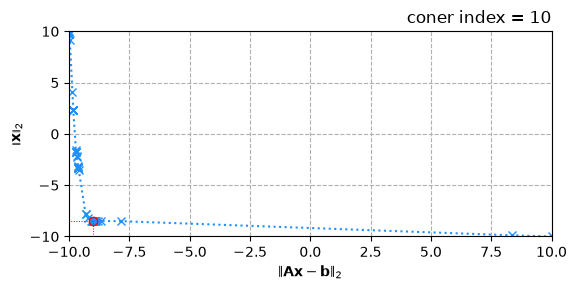

In [21]:
k_l = regchoice.lcurve_discrete(res_norms, sol_norms, plotit=True)
x_cgls = x_est_h[:,k_l]

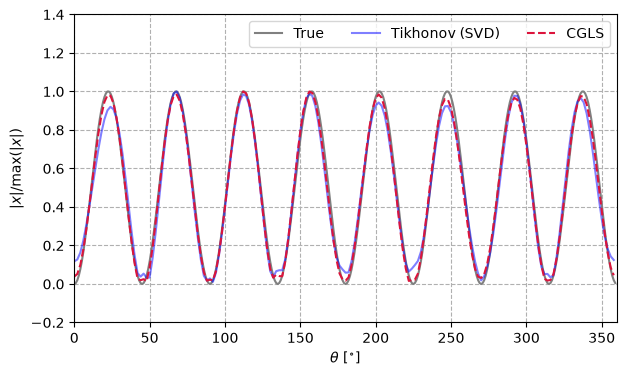

In [22]:
plt.figure(figsize = (7,4))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = "True")
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = "Tikhonov (SVD)", alpha = 0.5)
plt.plot(np.rad2deg(theta_dir), np.abs(x_cgls)/np.amax(np.abs(x_cgls)),
        '--', color = 'crimson',label = "CGLS")
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.4))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

# 5. Reconstrução

Uma vez obtida uma boa aproximação das amplitudes das ondas planas, podemos utilizá-la para prever o campo sonoro em posições nas quais não foram realizadas medições. Em outras palavras, desejamos **reconstruir** a grandeza de interesse em posições não observadas. Essas posições podem estar dentro do *apeture* do arranjo de microfones (interpolação) ou fora dele (extrapolação).

É importante destacar que a reconstrução é um **problema direto**. Como já estimamos a distribuição dos termos de fonte $\hat{\mathbf{x}}$ por meio da solução do problema inverso regularizado, basta calcular

\begin{equation}
\mathbf{b}_{\mathrm{r}} =
\mathbf{A}_{\mathrm{r}}\hat{\mathbf{x}},
\tag{7}
\end{equation}

em que $\mathbf{A}_{\mathrm{r}}$ é o operador direto avaliado nas posições desejadas para a reconstrução.

Vamos realizar um procedimento simples utilizando o objeto `problem` já criado:

- Definir as coordenadas dos pontos de reconstrução;
- Calcular a matriz de reconstrução;
- Reconstruir o campo sonoro utilizando a Eq. (7).

Utilizaremos a solução de Tikhonov calculada anteriormente. Também calcularemos um campo sonoro de referência nas coordenadas de reconstrução e, em seguida, compararemos os campos de pressão sonora reconstruído e de referência.

In [23]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
print("Shape of the reconstruction coord: {}".format(coord_recon.shape))

Shape of the reconstruction coord: (10000, 2)


In [24]:
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
print("Shape of the reconstruction matrix: {}".format(Arec.shape))

Shape of the reconstruction matrix: (10000, 180)


In [25]:
pres_recon = Arec @ x_tik
print("Shape of the reconstructed pressure: {}".format(pres_recon.shape))

Shape of the reconstructed pressure: (10000,)


### Campo acústico de referência

In [26]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.smooth_sf(q = factor)

### Comparação

Observe que, neste caso, em que a distribuição de ondas planas é suave, a reconstrução é bastante precisa, mesmo em posições distantes do *aperture* do arranjo de microfones.

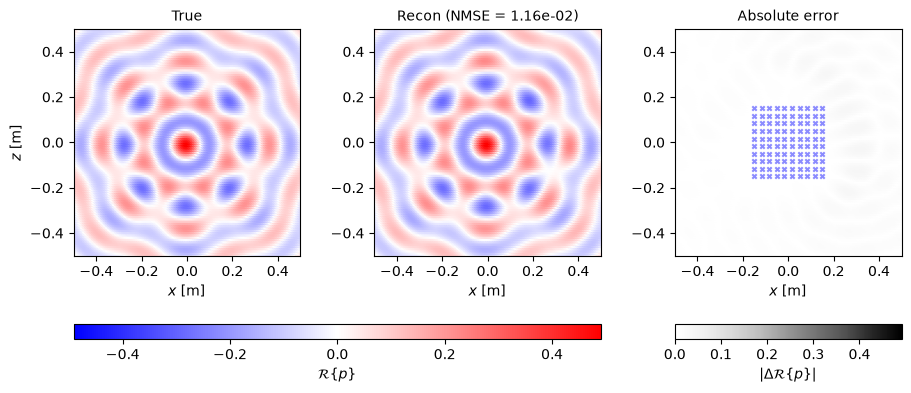

In [27]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)

### Amplitudes das ondas planas e energia espacial

A expansão em ondas planas se assemelha a uma representação de Fourier, mas sua matriz de sensibilidade geralmente não é unitária. As ondas planas candidatas não são necessariamente **ortogonais** sobre a abertura finita do arranjo de medição. Além disso, os vetores número de onda das ondas planas candidatas estão distribuídos sobre um círculo de raio $k_0$, em vez de uma grade cartesiana convencional da transformada discreta de Fourier (DFT). O número de ondas planas candidatas também pode ser maior do que o número de medições.

Consequentemente, o **teorema de Parseval** não estabelece uma relação direta entre a norma quadrática dos coeficientes das ondas planas e o valor quadrático médio da pressão sonora no espaço. É por esse motivo que as soluções foram apresentadas anteriormente de forma normalizada.

\begin{equation}
p_{\text{norm}} = \frac{|p|}{\text{max}(|p|)}
\end{equation}

Além disso, os valores numéricos dos coeficientes das ondas planas dependem da discretização angular. Para uma distribuição angular suave, aumentar o número de ondas planas candidatas geralmente reduz o módulo de cada coeficiente discreto.

Portanto, a norma quadrática das amplitudes estimadas das ondas planas não deve ser interpretada diretamente como a energia espacial da pressão sonora. Isso não invalida a reconstrução do campo sonoro, que normalmente é recuperado na mesma escala das medições, conforme ilustrado a seguir.

In [28]:
# Spatial mean squared pressure
E_space = np.mean(np.abs(ref.b_true)**2)

# Pressure reconstructed at the measurement positions
b_tik = Arec @ x_tik
E_recon = np.mean(np.abs(b_tik)**2)

# Squared norm of the estimated plane-wave coefficients
E_coeff = np.linalg.norm(x_tik)**2

print(f"Reference spatial mean square: {E_space:.4e}")
print(f"Reconstructed spatial mean square: {E_recon:.4e}")
print(f"Percentual error in energy: {100*(E_recon-E_space)/E_space:.2f} %")
print(f"Coefficient squared norm: {E_coeff:.4e}")

Reference spatial mean square: 1.0915e-02
Reconstructed spatial mean square: 1.1058e-02
Percentual error in energy: 1.31 %
Coefficient squared norm: 2.1125e-03


# 6. Análise e reconstrução de campos sonoros esparsos

Agora, podemos utilizar a classe `SoundField2D` para simular uma medição produzida por uma **distribuição esparsa** de ondas planas. Vamos criar um campo sonoro resultante da superposição de duas ondas planas.

Isso significa que, embora o campo sonoro medido seja suave, sua representação na base de vetores da solução é esparsa. Neste caso, apenas duas componentes são diferentes de zero. Dizemos que a solução é **$K$-esparsa**, com $K = 2$ neste exemplo.

Além disso, vamos reduzir o número de medições, criando um arranjo aleatório com $M = 40$ microfones.

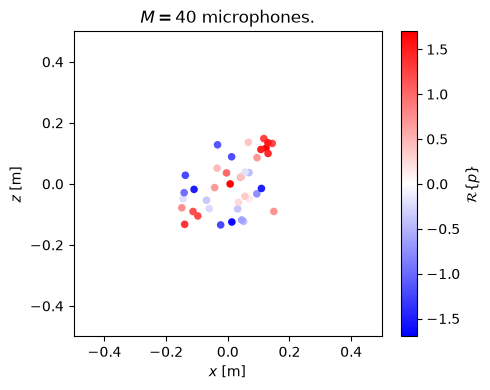

In [47]:
theta_deg = (45, 315)
amps = (1, 0.7)

# Forward problem
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_random_array(x_len = 0.3, z_len = 0.3, m = 40)
problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
noise_norm = 10**(-snr / 20) * np.linalg.norm(np.abs(problem.b_true))
plot_in_space(problem.coord, problem.b_noisy)

# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]
x_true[theta_deg_true==theta_deg[1]] = amps[1]

## 6.1. Solução de Tikhonov

Agora, podemos calcular a solução de Tikhonov para este caso. Observe que essa técnica de regularização favorece soluções que tendem a ser suaves, devido à penalização imposta pela norma $\ell_2$.

Observe que, embora a solução verdadeira seja esparsa (existem apenas duas componentes diferentes de zero, nos ângulos de $45^{\circ}$ e $315^{\circ}$), a solução obtida é suave, apresentando valores máximos próximos desses ângulos.

O leitor pode experimentar diferentes números de microfones, *aperture* do arranjo e outros parâmetros, observando seus efeitos sobre a solução, a reconstrução do campo sonoro e a coerência da matriz de sensibilidade.

In [54]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
u, s, v = regsolvers.csvd(problem.A)

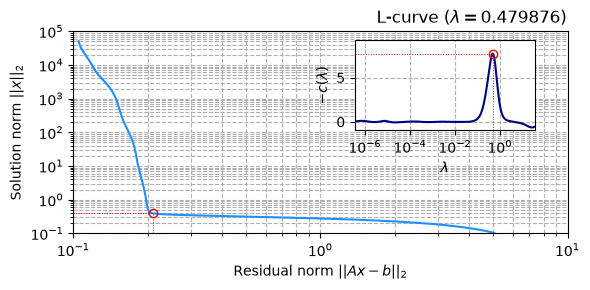

In [55]:
lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method
x_tik = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter

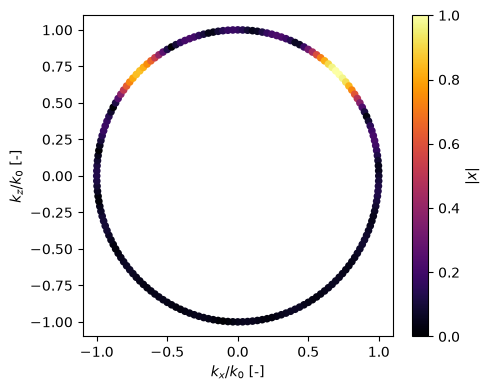

In [32]:
problem.plot_solution_field(x_tik)

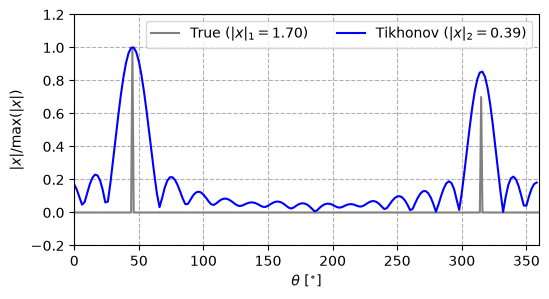

In [56]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)))
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = r"Tikhonov ($|x|_2 = ${:.2f})".format(np.linalg.norm(x_tik, 2)), alpha = 1)
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## Reconstrução versus referência

Com uma distribuição esparsa de ondas planas e um número relativamente pequeno de sensores, a reconstrução é precisa apenas nas proximidades das posições de medição.

A regularização de Tikhonov convencional, que favorece soluções suaves, não é adequada para representar um espectro angular esparso, como podemos observar nas soluções normalizadas apresentadas nos gráficos.

In [57]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
pres_recon = Arec @ x_tik

In [58]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.compute_pres(theta_deg = theta_deg, amps = amps)

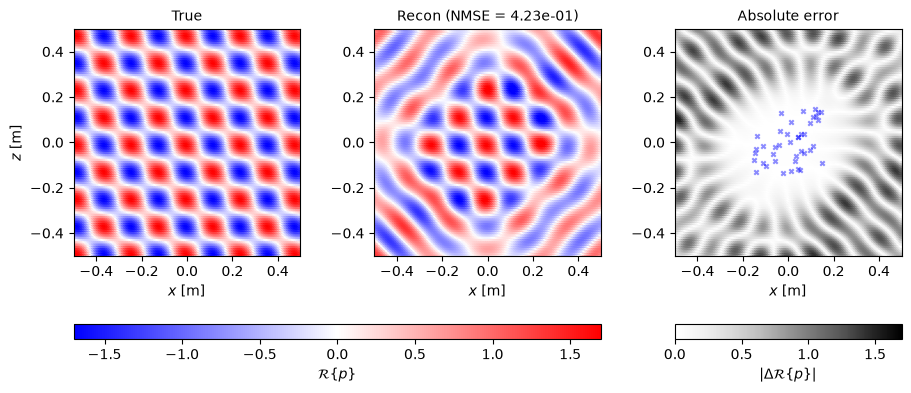

In [59]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)

# 7. Regularização esparsa e *compressed sensing*

Nos exemplos anteriores, utilizamos a regularização de Tikhonov (e o CGLS) para estimar as amplitudes das ondas planas. Embora essa abordagem possa reconstruir o campo sonoro com precisão, ela não necessariamente recupera um espectro angular esparso.

Considere o campo sonoro composto por apenas duas ondas planas. Idealmente, seu espectro angular deveria conter apenas dois coeficientes **diferentes de zero**. Isso sugere que devemos incorporar a **esparsidade** à formulação do problema inverso.

### A pseudonorma $\ell_0$

Uma medida natural de esparsidade é a pseudonorma $\ell_0$, que conta o número de coeficientes diferentes de zero, sendo definida por

\begin{equation}
\|\mathbf{x}\|_0 = \#\{i:x_i\neq 0\},
\tag{8}
\end{equation}

Podemos, portanto, resolver

\begin{equation}
\begin{gathered}
\text{min}(\left\|\textbf{x}\right\|_{0}), \ \ \, \text{sujeito a} \ \ \ \left\|\textbf{Ax - b}\right\|^{2}_{2} \leq k \left\|\textbf{n}\right\|^{2}_{2} \\ \text{ou} \\
\hat{\mathbf{x}} = \operatorname*{arg\,min}_{\mathbf{x}}\left\{\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2 + \lambda\|\mathbf{x}\|_0\right\}.
\end{gathered}
\tag{9}
\end{equation}

A **norma do resíduo** mede a concordância entre o modelo e as observações, enquanto a pseudonorma $\ell_0$ da solução penaliza o número de ondas planas ativas (quanto maior o número de coeficientes ativos, maior a penalização).

Infelizmente, a minimização da pseudonorma $\ell_0$ constitui um problema de otimização **não convexo** e **combinatório**, geralmente difícil de resolver em sistemas de grandes dimensões.

### A relaxação $\ell_1$

Uma alternativa prática é substituir a pseudonorma $\ell_0$ pela norma convexa $\ell_1$,

\begin{equation}
\|\mathbf{x}\|_1 = \sum_{i=1}^{L}|x_i|.
\tag{10}
\end{equation}

Isso conduz às seguintes formulações:

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|_{1}), \ \ \, \text{sujeito a} \ \ \ \left\|\textbf{Ax - b}\right\|_{2} \leq k \left\|\textbf{n}\right\|_{2}
\tag{11}
\end{equation}

ou ao problema de **LASSO** (*Least Absolute Shrinkage and Selection Operator*), dado por

\begin{equation}
\hat{\mathbf{x}}_\lambda = \operatorname*{arg\,min}_{\mathbf{x}}\left\{\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2+\lambda\|\mathbf{x}\|_1\right\}.
\tag{12}
\end{equation}

Diferentemente da penalização quadrática $\ell_2$ utilizada na regularização de Tikhonov convencional, a penalização $\ell_1$ favorece soluções nas quais alguns coeficientes se tornam exatamente iguais a zero. Assim, a solução resultante pode identificar um pequeno número de direções dominantes de propagação das ondas planas, ao mesmo tempo em que se ajusta ao campo sonoro medido.

Essa é uma das ideias centrais do *compressed sensing*, no qual sinais esparsos podem ser recuperados a partir de um número limitado de medições, desde que determinadas condições sobre a matriz de sensibilidade sejam satisfeitas.

## 7.1. Por que a norma $\ell_1$ favorece a esparsidade?

Considere duas ondas planas cujas contribuições para a pressão sonora medida são praticamente indistinguíveis. Nessa situação, o mesmo campo sonoro pode ser aproximado concentrando a amplitude em uma única direção ou distribuindo-a entre várias direções próximas.

A penalização quadrática $\ell_2$ favorece a distribuição da amplitude, pois dividir um coeficiente em contribuições menores reduz a soma de seus quadrados. A penalização $\ell_1$, por outro lado, não oferece essa vantagem. Mais importante ainda, a penalização $\ell_1$ pode forçar coeficientes pequenos a se tornarem exatamente iguais a zero.

Para compreender esse comportamento, considere um problema inverso escalar simples, com uma incógnita real:

$$
\hat{x}=\operatorname*{arg\,min}_x
\left\{\frac12(x-b)^2+\lambda|x|\right\}.
$$

Sua solução é dada pelo **operador de limiarização suave** (*soft-thresholding*):

$$
\hat{x}=
\begin{cases}
b-\lambda, & b>\lambda,\\
0, & |b|\leq\lambda,\\
b+\lambda, & b<-\lambda.
\end{cases}
$$

Portanto, coeficientes abaixo de determinado limiar são anulados, enquanto os coeficientes maiores têm suas amplitudes reduzidas.

Isso explica o comportamento da regularização $\ell_1$ em favorecer a esparsidade: a solução pode preservar algumas componentes dominantes enquanto suprime contribuições mais fracas.

Para uma matriz de sensibilidade geral, os coeficientes interagem por meio do modelo direto. Portanto, a solução não pode ser obtida simplesmente aplicando a limiarização a cada coeficiente de forma independente. Ainda assim, o mesmo mecanismo fundamental favorece soluções esparsas.

Agora podemos experimentar soluções esparsas utilizando as Eqs. (11) e (12). Os solucionadores estão implementados no módulo `regsolvers` do `PyRegTools`. Vamos observar como eles se comportam.


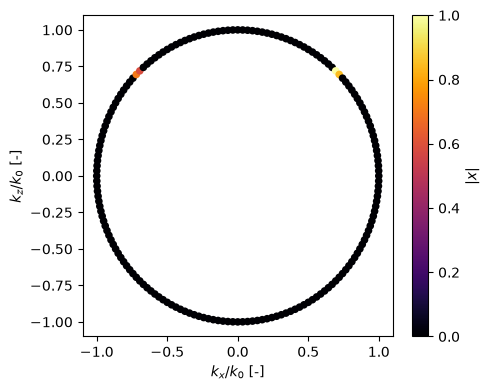

In [60]:
x_cs = regsolvers.cvx_constrained(problem.A, problem.b_noisy, noise_norm, is_cs = True, is_complex = True)
problem.plot_solution_field(x_cs)

In [61]:
x_cs_norm = x_cs/np.amax(np.abs(x_cs))
ind_tol = np.where(x_cs_norm >= 1e-4)
print("Shape of full solution: {}".format(x_cs.shape))
print("Shape of coefficients above -40 dB: {}".format(ind_tol[0].shape))

Shape of full solution: (180,)
Shape of coefficients above -40 dB: (7,)


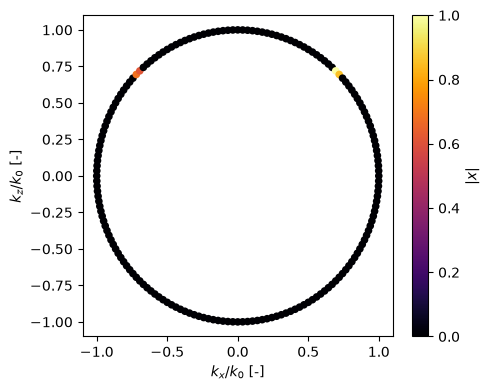

In [62]:
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, 0.25, is_lasso = True, is_complex = True)
problem.plot_solution_field(x_lasso)

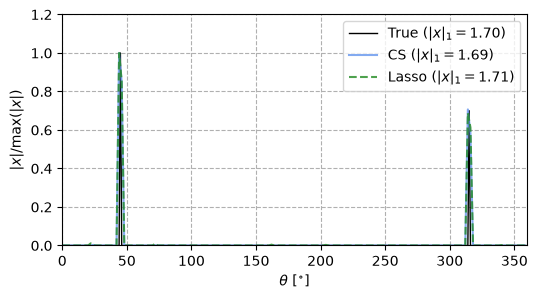

In [63]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_cs)/np.amax(np.abs(x_cs)), 
        '-', color = 'cornflowerblue', label = r"CS ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_cs, 1)), alpha = 0.8)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_lasso, 1)), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## Reconstrução vs. referência

Vamos reconstruir o campo sonoro utilizando a **solução esparsa** (`x_cs` ou `x_lasso`). Observe que a reconstrução é bastante precisa, mesmo em posições fora do *aperture* do arranjo de microfones, apesar do número reduzido de sensores. Volte algumas células e compare esse resultado com a reconstrução obtida pela regularização de Tikhonov.

É claro que, neste caso, temos uma certa vantagem, pois sabemos que o campo sonoro possui uma representação **$K=2$-esparsa**. Em situações reais, geralmente não conhecemos, *a priori*, o grau de esparsidade do campo sonoro.

Ainda assim, essa demonstração cumpre seu objetivo como exemplo introdutório das vantagens da regularização esparsa.

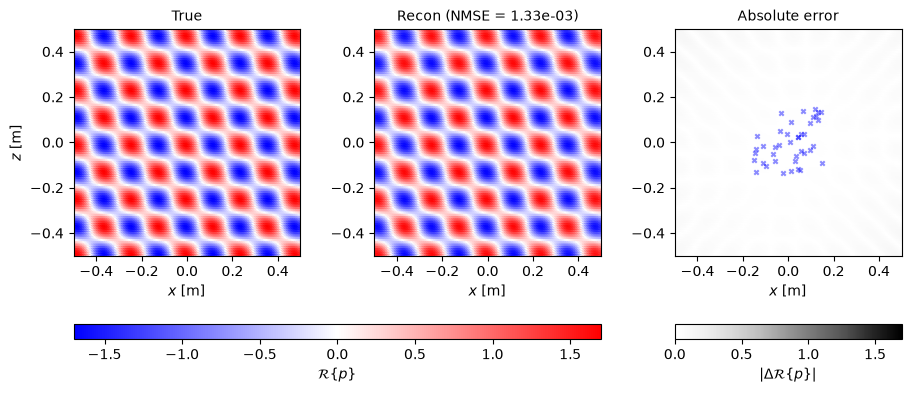

In [64]:
pres_recon = Arec @ x_cs
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)    

## 7.2. Condições para a recuperação esparsa

No exemplo anterior, utilizamos a regularização $\ell_1$ para reconstruir um campo sonoro gerado por um pequeno número de ondas planas. O espectro angular estimado foi esparso, contendo apenas alguns coeficientes significativos.

Entretanto, **a recuperação esparsa nem sempre é garantida**. Seu sucesso depende do número de ondas planas ativas ($K$), do número de medições ($M$) e das propriedades da matriz de sensibilidade.

Considere o problema inverso linear $\mathbf{Ax} = \mathbf{b}$. Assumimos que o vetor de coeficientes verdadeiro é $K$-esparso, ou seja,

\begin{equation}
\|\mathbf{x}\|_0 = K,
\end{equation}

em que $K$ representa o número de coeficientes diferentes de zero.

### 7.2.1. Coerência mútua

Uma condição importante para a recuperação esparsa é que as diferentes colunas da matriz de sensibilidade sejam suficientemente distinguíveis entre si.

A **coerência mútua** de $\mathbf{A}$ é definida por

\begin{equation}
\mu(\mathbf{A}) =
\max_{i\neq j}
\frac{|\mathbf{a}_i^H\mathbf{a}_j|}
{\|\mathbf{a}_i\|_2\|\mathbf{a}_j\|_2},
\tag{13}
\end{equation}

em que $\mathbf{a}_i$ representa a $i$-ésima coluna de $\mathbf{A}$.

A coerência mútua mede a maior correlação normalizada entre duas colunas distintas. Seus valores estão compreendidos entre zero e um:

- $\mu(\mathbf{A})=0$ indica que as colunas são mutuamente ortogonais (o caso ideal);
- $\mu(\mathbf{A})=1$ indica que pelo menos duas colunas são linearmente dependentes.

No nosso problema de análise de campos sonoros, cada coluna representa o campo de pressão sonora produzido por uma onda plana, amostrado nas posições dos microfones. Assim, se duas colunas apresentam alta correlação, torna-se difícil distinguir suas respectivas direções de propagação a partir das medições.

Observe também que, neste caso, a coerência da matriz de sensibilidade depende de diversos fatores (veja a Eq. (6)):

- As coordenadas do arranjo de microfones, que dependem do número de sensores e da abertura do arranjo;
- O número de ondas planas candidatas: à medida que esse número aumenta, as direções angulares ficam mais próximas, tornando as ondas planas vizinhas cada vez mais semelhantes e, consequentemente, aumentando a coerência mútua.

#### Coerência mútua e esparsidade

Para o problema inverso sem ruído, uma condição suficiente clássica para a recuperação exata de uma solução $K$-esparsa por meio da minimização $\ell_1$ é

\begin{equation}
\mu(\mathbf{A}) < \frac{1}{2K-1}.
\tag{14}
\end{equation}

Esse resultado pressupõe que as colunas estejam normalizadas e que a recuperação seja realizada utilizando a formulação com restrição de igualdade:

\begin{equation}
\min_{\mathbf{x}}\|\mathbf{x}\|_1
\quad \text{sujeito a} \quad
\mathbf{A}\mathbf{x}=\mathbf{b}.
\end{equation}

Por exemplo, se o campo sonoro contém apenas duas ondas planas ($K=2$), a condição suficiente se torna

\begin{equation}
\mu(\mathbf{A}) < \frac{1}{3}.
\end{equation}

Portanto, a recuperação de um número maior de ondas planas exige uma matriz de sensibilidade com menor coerência mútua para satisfazer essa condição.

É importante destacar que essa é uma **condição suficiente, mas não necessária**. A recuperação esparsa ainda pode ser bem-sucedida mesmo quando a desigualdade não é satisfeita — o que veremos a seguir.

No `PyRegTools`, a coerência mútua pode ser calculada com o método `gram_matrix` do módulo `regsolvers`. Vamos realizar um pequeno experimento variando o número de ondas planas candidatas no nosso modelo.

In [65]:
n_waves = np.arange(20, 370, 10)
coherence = np.zeros(len(n_waves))
nmse = np.zeros(len(n_waves))
for jn, nw in enumerate(n_waves):
    # Matrix coherence
    problem.get_sens_mtx(nwaves = nw)
    gram_mtx, coherence[jn] = regsolvers.gram_matrix(problem.A)
    # solution and reconstruction
    x_cs = regsolvers.cvx_constrained(problem.A, problem.b_noisy, noise_norm, is_cs = True, is_complex = True)
    theta_dir = problem.wave_directions()
    k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
    Arec = np.exp(-1j * coord_recon @ k_rec_vec)
    pres_recon = Arec @ x_cs
    nmse[jn] = pyregtools.utils.nmse_fun(x_ref=ref.b_true, x_meas=pres_recon)

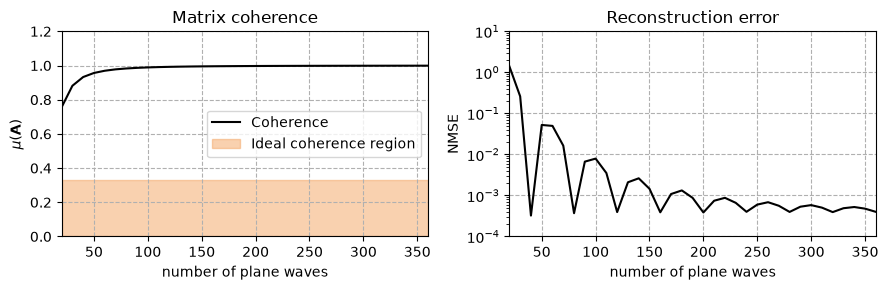

In [66]:
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(n_waves, coherence, 'k', label = 'Coherence')
axs[0].fill_between(n_waves, np.zeros(len(n_waves)), (1/3)*np.ones(len(n_waves)), 
                    alpha = 0.5, color = 'sandybrown', label = 'Ideal coherence region')
axs[0].legend(loc = 'center right')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((n_waves[0], n_waves[-1]))
axs[0].set_ylim((0,1.2))
axs[0].set_xlabel(r'number of plane waves')
axs[0].set_ylabel(r'$\mu(\mathbf{A})$')
axs[0].set_title(r'Matrix coherence')
axs[1].semilogy(n_waves, nmse, color = 'k')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((n_waves[0], n_waves[-1]))
axs[1].set_ylim((1e-4, 10))
axs[1].set_xlabel(r'number of plane waves')
axs[1].set_ylabel(r'NMSE')
axs[1].set_title(r'Reconstruction error')
plt.tight_layout()

### 7.2.2. Quantas medições são necessárias?

Outra questão importante é determinar quantos microfones são necessários para recuperar um espectro angular $K$-esparso. Sob condições adequadas sobre a matriz de sensibilidade, a teoria de *compressed sensing* fornece a seguinte relação de escala:

\begin{equation}
M \gtrsim C K \log\left(\frac{L}{K}\right),
\tag{15}
\end{equation}

em que $C$ depende da matriz de sensibilidade e das garantias de recuperação desejadas. A constante $C$ nessa relação não é universal. Seu valor depende do modelo da matriz de sensibilidade, do algoritmo de recuperação e da probabilidade e precisão desejadas para a recuperação.

Consequentemente, essa relação deve ser interpretada como uma lei de escala teórica, e não como uma fórmula para calcular o número exato de medições necessárias.

Essa relação indica que sinais esparsos podem, em determinadas condições, ser reconstruídos utilizando um número de medições substancialmente menor do que o número de coeficientes desconhecidos ($M\ll L$). Em particular, essa relação clássica é estabelecida sob determinadas hipóteses sobre a matriz de sensibilidade, que não são necessariamente satisfeitas pelas matrizes de ondas planas consideradas aqui. Para nosso problema de análise de campos sonoros, o número de microfones necessário para uma recuperação esparsa confiável deve, portanto, ser investigado em conjunto com a geometria do arranjo, a abertura de medição, a frequência e a discretização angular.

Entretanto, essa relação é estabelecida para classes específicas de matrizes de sensibilidade e não pode ser aplicada diretamente a um arranjo arbitrário de microfones.

### 7.2.3. Propriedade da isometria restrita (RIP)

Outro conceito importante no sensoriamento compressivo é a **Propriedade da Isometria Restrita** (*Restricted Isometry Property*, RIP), que descreve a capacidade de uma matriz de sensibilidade preservar a norma euclidiana de vetores esparsos.

Considere uma matriz de sensibilidade $\mathbf{A}\in\mathbb{C}^{M\times L}$, cujas colunas estejam normalizadas para apresentar norma euclidiana unitária. A matriz satisfaz a RIP de ordem $K$, com constante de isometria restrita $\delta_K$, se

\begin{equation}
(1-\delta_K)\|\mathbf{x}\|_2^2
\leq
\|\mathbf{A}\mathbf{x}\|_2^2
\leq
(1+\delta_K)\|\mathbf{x}\|_2^2.
\tag{16}
\end{equation}

para todo vetor $\mathbf{x}\in\mathbb{C}^L$ contendo, no máximo, $K$ coeficientes diferentes de zero.

O menor valor não negativo de $\delta_K$ que satisfaz essas desigualdades é denominado **constante de isometria restrita**.

#### Interpretação física

No nosso problema de reconstrução de campos sonoros, $\mathbf{x}$ representa as amplitudes das ondas planas candidatas, enquanto $\mathbf{A}\mathbf{x}$ representa as pressões sonoras resultantes nas posições de medição.

A RIP estabelece que, para qualquer combinação de até $K$ ondas planas, a matriz de sensibilidade preserva aproximadamente a norma euclidiana quadrática do vetor de coeficientes.

Se $\delta_K$ é pequeno, diferentes combinações esparsas de ondas planas têm menor probabilidade de se tornarem indistinguíveis após a medição.

Observe que a RIP se aplica apenas a **vetores esparsos**. Ela não exige que a matriz de sensibilidade preserve a norma de todos os vetores possíveis, o que geralmente seria impossível quando $M<L$.

#### Por que a RIP é útil?

A RIP fornece garantias teóricas para a unicidade e a estabilidade da reconstrução esparsa.

Por exemplo, a diferença entre dois vetores $K$-esparsos pode conter até $2K$ coeficientes diferentes de zero. Portanto, se

\begin{equation}
\delta_{2K}<1,
\end{equation}

a matriz de sensibilidade não pode mapear dois vetores $K$-esparsos distintos para o mesmo conjunto de medições. Isso garante a unicidade da representação esparsa.

Condições mais rigorosas sobre a RIP também garantem a recuperação bem-sucedida por meio da minimização $\ell_1$. Uma condição suficiente clássica é

\begin{equation}
\delta_{2K}<\sqrt{2}-1.
\end{equation}

Sob essa condição, o método de *basis pursuit* pode recuperar exatamente um sinal $K$-esparso a partir de medições sem ruído. Resultados relacionados também garantem a estabilidade da reconstrução na presença de ruído.

Essas condições são **suficientes, mas não necessárias**: a recuperação esparsa pode ser bem-sucedida mesmo quando os limites estabelecidos pela RIP não são satisfeitos.

#### Relação com a coerência mútua

A RIP está intimamente relacionada à coerência mútua da matriz de sensibilidade. As constantes de isometria restrita satisfazem:

\begin{equation}
\delta_K\leq(K-1)\mu(\mathbf{A}).
\end{equation}

Assim, uma baixa coerência mútua fornece um limite superior para a constante RIP.

Entretanto, esse limite pode ser conservador. Uma matriz pode apresentar constantes de isometria restrita aceitáveis, mesmo quando a estimativa baseada na coerência é grande demais para estabelecer uma garantia útil.

#### Qual é a dificuldade de avaliar a RIP?

Diferentemente da coerência mútua, que pode ser calculada diretamente a partir da matriz de Gram, a avaliação das constantes RIP apresenta um custo computacional elevado.

Para uma determinada ordem $K$, é necessário considerar todos os subconjuntos possíveis $S$ de $K$ colunas de $\mathbf{A}$ e examinar os autovalores de

\begin{equation}
\mathbf{A}_S^H\mathbf{A}_S,
\end{equation}

em que $\mathbf{A}_S$ contém apenas as colunas selecionadas. O número de subconjuntos possíveis é

\begin{equation}
\binom{L}{K}=\frac{L!}{K!(L-K)!},
\end{equation}

que cresce rapidamente com $L$ e $K$.

Consequentemente, o cálculo exato das constantes RIP geralmente é impraticável para matrizes de sensibilidade de grandes dimensões. Na prática, pesquisadores frequentemente utilizam limites teóricos, coerência mútua ou experimentos numéricos com subconjuntos selecionados aleatoriamente.

#### Implicações para a reconstrução de campos sonoros

Para nossa matriz de sensibilidade baseada em ondas planas, direções candidatas próximas podem gerar colunas fortemente correlacionadas, especialmente em baixas frequências ou quando a abertura do arranjo de microfones é pequena. Isso pode produzir constantes de isometria restrita elevadas, dificultando o estabelecimento de garantias teóricas de recuperação.

Por esse motivo, **a coerência mútua é um indicador mais prático**, enquanto a RIP fornece uma explicação teórica mais abrangente sobre a importância da geometria da matriz de sensibilidade para a recuperação esparsa.

## 7.3. Escolha do parâmetro de regularização para o Lasso

Até aqui, consideramos duas abordagens para a reconstrução esparsa. A primeira é a formulação com restrição, também conhecida como **basis pursuit denoising**:

\begin{equation}
\hat{\mathbf{x}} =
\operatorname*{arg\,min}_{\mathbf{x}}
\|\mathbf{x}\|_1
\quad
\text{sujeito a}
\quad
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2 \leq k \ \left\|\textbf{n}\right\|^{2}_{2},
\end{equation}

Na prática, entretanto, o nível de ruído pode não ser conhecido com precisão. Além disso, o resíduo pode conter erros de modelagem, como aqueles causados pela discretização das direções das ondas planas candidatas. Escolher $k \ \left\|\textbf{n}\right\|_{2}$ muito pequeno pode tornar o problema de otimização inviável.

Uma alternativa é a **formulação penalizada do Lasso**:

\begin{equation}
\hat{\mathbf{x}}_\lambda =
\operatorname*{arg\,min}_{\mathbf{x}}
\left\{
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2
+
\lambda\|\mathbf{x}\|_1
\right\}.
\end{equation}

Nesse caso, $\lambda$ controla o compromisso entre o ajuste às medições e a promoção da esparsidade. Valores pequenos permitem que mais coeficientes contribuam para a reconstrução, enquanto valores elevados favorecem soluções mais esparsas, potencialmente às custas da precisão da reconstrução.

Diversas estratégias podem ser utilizadas para selecionar $\lambda$.

### 7.3.1. Princípio da discrepância

Se o nível de ruído é conhecido, podemos selecionar $\lambda$ de modo que a norma do resíduo seja aproximadamente igual à norma esperada do ruído:

\begin{equation}
\|\mathbf{A}\hat{\mathbf{x}}_\lambda-\mathbf{b}\|_2
\approx \epsilon.
\end{equation}

Isso evita que a solução se ajuste desnecessariamente ao ruído das medições. Entretanto, o método exige uma estimativa confiável do nível de ruído e deve considerar possíveis erros de modelagem.

### 7.3.2. Curva-L

A curva-L representa o compromisso entre a norma do resíduo e a penalização de regularização:

\begin{equation}
\left(
\log\|\mathbf{A}\hat{\mathbf{x}}_\lambda-\mathbf{b}\|_2,
\quad
\log\|\hat{\mathbf{x}}_\lambda\|_1
\right).
\end{equation}

Uma solução próxima a um canto bem definido pode representar um compromisso razoável entre o ajuste aos dados e a esparsidade.

Entretanto, diferentemente da regularização de Tikhonov convencional, o conjunto de coeficientes ativos na solução do Lasso pode mudar à medida que $\lambda$ varia, produzindo irregularidades na curva. Consequentemente, a detecção automática do canto pode ser menos confiável.

### 7.3.3. Validação cruzada

Outra possibilidade é dividir as medições em conjuntos de treinamento e validação.

Para cada valor candidato de $\lambda$, a solução é estimada utilizando os microfones do conjunto de treinamento e avaliada por meio da previsão da pressão sonora nos microfones do conjunto de validação.

O parâmetro é selecionado minimizando o erro de validação:

\begin{equation}
\lambda_{\mathrm{CV}} =
\operatorname*{arg\,min}_{\lambda}
\|\mathbf{A}_{\mathrm{val}}
\hat{\mathbf{x}}_{\lambda,\mathrm{train}}
-\mathbf{b}_{\mathrm{val}}\|_2^2.
\end{equation}

Essa abordagem não exige conhecimento prévio da norma do ruído. Entretanto, o parâmetro que melhor prevê o campo de pressão sonora pode não ser necessariamente aquele que fornece a identificação mais precisa das direções das ondas planas.

#### Validação cruzada generalizada (GCV)

A validação cruzada generalizada (*Generalized Cross-Validation*, GCV) é amplamente utilizada para selecionar parâmetros de regularização em problemas inversos lineares, particularmente na regularização de Tikhonov.

Entretanto, **a GCV clássica não pode ser aplicada diretamente ao Lasso**, pois a solução do Lasso é, em geral, uma função não linear das medições. Extensões baseadas no número efetivo de graus de liberdade são possíveis, mas exigem hipóteses e implementações adicionais.

### Explorando a trajetória de regularização

Uma maneira interessante de investigar o Lasso é resolver o problema para diferentes valores de $\lambda$ e observar como a norma do resíduo, os módulos dos coeficientes e o número de coeficientes ativos se modificam.

Para nossa função objetivo, a solução se torna identicamente nula quando

\begin{equation}
\lambda\geq\lambda_{\max} =
2\|\mathbf{A}^H\mathbf{b}\|_\infty.
\end{equation}

Portanto, $\lambda_{\max}$ fornece um limite superior natural para a busca do parâmetro de regularização.

No exemplo a seguir, exploraremos a trajetória de regularização do Lasso e compararemos diferentes estratégias de seleção do parâmetro para a reconstrução de um espectro esparso de ondas planas.


In [67]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
lambda_max = 2 * np.max(np.abs(problem.A.conj().T @ problem.b_noisy))
lambda_grid = lambda_max * np.logspace(-5, 0, 20)

In [68]:
x_lasso_list = []
sol_norms = np.zeros(len(lambda_grid))
res_norms = np.zeros(len(lambda_grid))
nmse = np.zeros(len(lambda_grid))
num_active = np.zeros(len(lambda_grid))
for j, lam in enumerate(lambda_grid):
    x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, lam, is_lasso = True, is_complex = True)
    x_lasso_list.append(x_lasso)
    x_norm = np.abs(x_lasso)/np.amax(np.abs(x_lasso))
    num_active[j] = len(np.where(x_lasso >= 1e-2)[0])
    sol_norms[j] = np.linalg.norm(x_lasso, 1)
    res_norms[j] = np.linalg.norm(problem.A @ x_lasso - problem.b_noisy, 2)
    pres_recon = Arec @ x_lasso
    nmse[j] = pyregtools.utils.nmse_fun(x_ref=ref.b_true, x_meas=pres_recon)

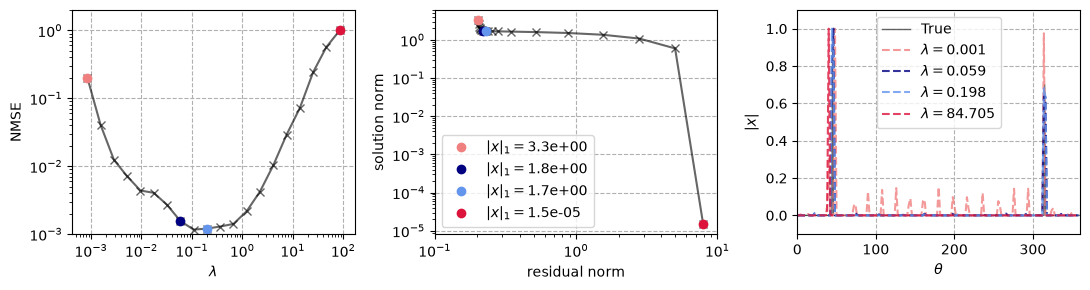

In [72]:
idx2plt = [0, 7, 9, 19]
colors = ['lightcoral', 'navy', 'cornflowerblue', 'crimson']

fig, axs = plt.subplots(1, 3, figsize = (11,3))
axs[0].loglog(lambda_grid, nmse, 'x-k', alpha = 0.6)
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0.5*lambda_grid[0], 2*lambda_grid[-1]))
axs[0].set_ylim((1e-3, 2.0))
axs[0].set_xlabel(r'$\lambda$')
axs[0].set_ylabel(r'NMSE')

axs[1].loglog(res_norms, sol_norms, '-xk', alpha = 0.6)
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'residual norm')
axs[1].set_ylabel(r'solution norm')
axs[1].set_xlim((0.1, 10))
#axs[1].set_ylim((1, 10))

axs[2].plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', alpha = 0.6, label = "True", linewidth = 1.0)
for i, idx in enumerate(idx2plt):
    axs[0].loglog(lambda_grid[idx], nmse[idx], 'o', color = colors[i])
    axs[1].loglog(res_norms[idx], sol_norms[idx], 'o', color = colors[i], 
                  label = r"$|x|_1 = ${:.1e}".format(np.linalg.norm(x_lasso_list[idx], 1)))
    axs[2].plot(np.rad2deg(theta_dir), np.abs(x_lasso_list[idx])/np.amax(np.abs(x_lasso_list[idx])), 
        '--', color = colors[i], label = r"$\lambda = {:.3f}$".format(lambda_grid[idx]), alpha = 0.8)
axs[1].legend()
axs[2].legend()
axs[2].grid(linestyle = '--')
axs[2].set_xlim((0, 360))
axs[2].set_ylim((-0.1, 1.1))
axs[2].set_xlabel(r'$\theta$')
axs[2].set_ylabel(r'$|x|$')
plt.tight_layout()


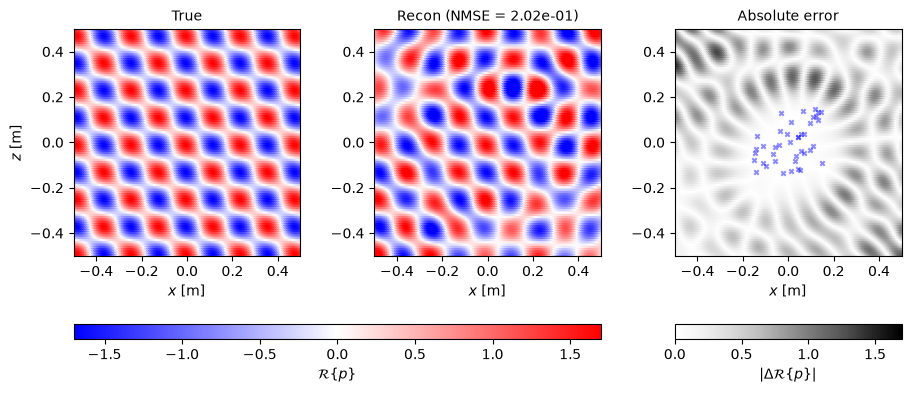

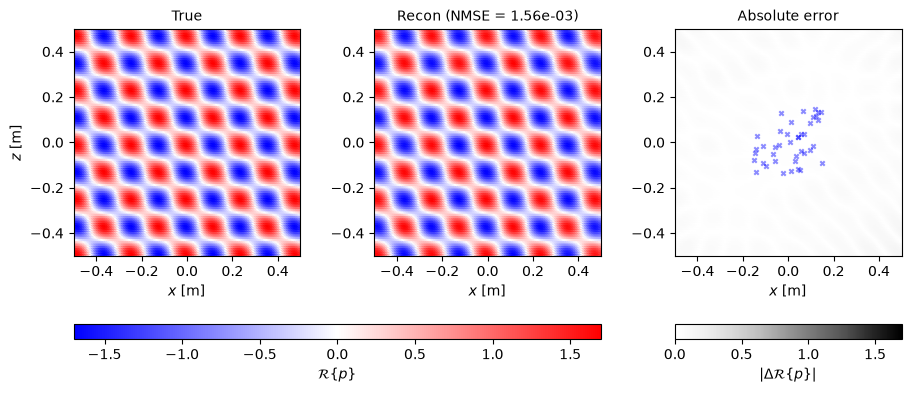

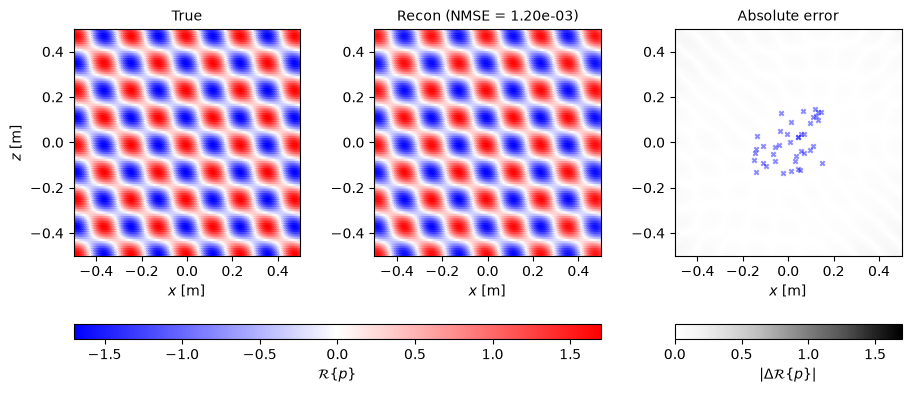

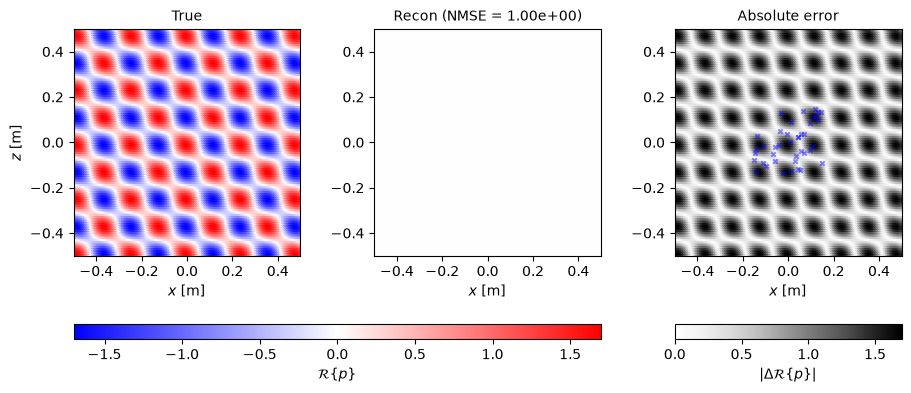

In [73]:
for i in idx2plt:
    pres_recon = Arec @ x_lasso_list[i]
    compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)    

## 7.4. Princípio da discrepância

Vamos observar como podemos aproveitar a infraestrutura do `PyRegTools`. No módulo `regchoice`, a função `discrep` foi desenvolvida especificamente para a regularização de Tikhonov, utilizando a SVD da matriz de sensibilidade.

Dada a simplicidade do princípio da discrepância, é fácil implementar uma função que resolva o problema Lasso, calcule a norma do resíduo e retorne:

\begin{equation}
\text{DP}(\lambda) = \|\mathbf{A}\mathbf{x}_{\lambda}-\mathbf{b}\|_2^2 - \|\mathbf{n}\|_2^2
\end{equation}

Em seguida, podemos passar essa função para `scipy.optimize.brentq`, que permite encontrar o valor de $\lambda$ para o qual $\text{DP}(\lambda)=0$.

Vamos observar como isso funciona e visualizar a solução obtida e a reconstrução do campo sonoro.

In [77]:
def discrep_fun(lam, A, b, noise_norm):
    x_lasso = regsolvers.cvx_reg(A, b, lam, is_lasso = True, is_complex = True)
    res_norm = np.linalg.norm(A @ x_lasso - b)
    return res_norm**2 - noise_norm**2

In [78]:
lam_opt = scipy.optimize.brentq(discrep_fun, lambda_grid[0], lambda_grid[-1], args=(problem.A, problem.b_noisy, noise_norm))

In [79]:
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, lam_opt, is_lasso = True, is_complex = True)

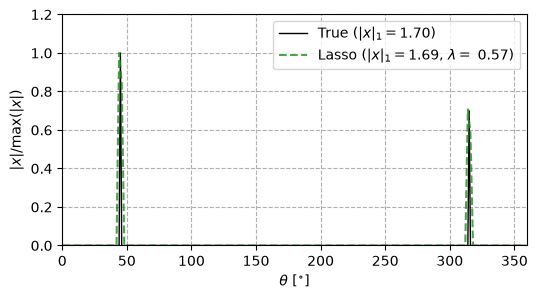

In [80]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f}, $\lambda = $ {:.2f})".format(np.linalg.norm(x_lasso, 1), lam_opt), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

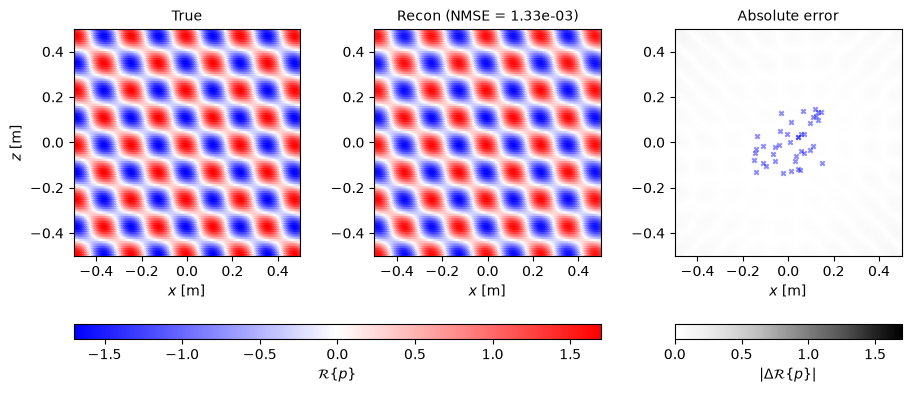

In [81]:
pres_recon = Arec @ x_lasso
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon) 

## 7.5. Quando a esparsidade não é uma hipótese adequada

Até aqui, consideramos campos sonoros compostos por um pequeno número de ondas planas dominantes, para os quais a regularização $\ell_1$ é particularmente interessante. Entretanto, nem todo campo sonoro admite uma representação esparsa. Como contraexemplo, vamos considerar uma **distribuição angular suave de ondas planas**, na qual muitas direções de propagação contribuem para o campo sonoro.

Vamos reconstruir essa distribuição utilizando a regressão Lasso. Como a penalização $\ell_1$ promove a esparsidade, o espectro angular reconstruído pode apresentar um pequeno número de picos concentrados, em vez de reproduzir a distribuição suave original. Esses coeficientes esparsos ainda podem fornecer uma aproximação razoável do campo de pressão sonora medido (ou não).

Esse exemplo evidencia uma distinção importante: **um resíduo de reconstrução pequeno não implica necessariamente uma recuperação precisa da distribuição de ondas planas que gerou o campo sonoro**.

A escolha da regularização deve, portanto, refletir a estrutura física esperada para a solução. Enquanto a regularização $\ell_1$ é adequada para campos dominados por poucas ondas planas discretas, espectros angulares suaves ou distribuídos podem ser mais bem representados utilizando a regularização $\ell_2$ ou outras informações *a priori* que promovam explicitamente a suavidade da solução.

In [82]:
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_random_array(x_len = 0.3, z_len = 0.3, m = 40)
factor = 4
problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2

In [83]:
problem.get_sens_mtx(nwaves = 180)
lambda_max = 2 * np.max(np.abs(problem.A.conj().T @ problem.b_noisy))
reg_min = scipy.optimize.brentq(discrep_fun, lambda_grid[0], lambda_grid[-1], args=(problem.A, problem.b_noisy, noise_norm))
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, reg_min, is_lasso = True, is_complex = True)

In [84]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
pres_recon = Arec @ x_lasso

In [85]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.smooth_sf(q = factor)

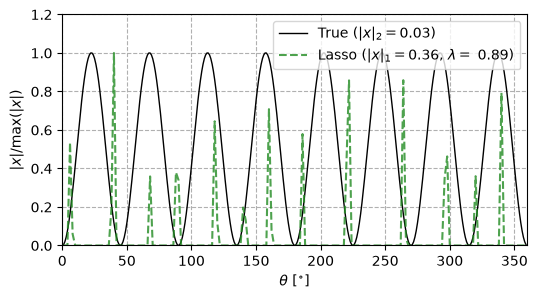

In [86]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_2 = ${:.2f})".format(np.linalg.norm(x_true, 2)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f}, $\lambda = $ {:.2f})".format(np.linalg.norm(x_lasso, 1), reg_min), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

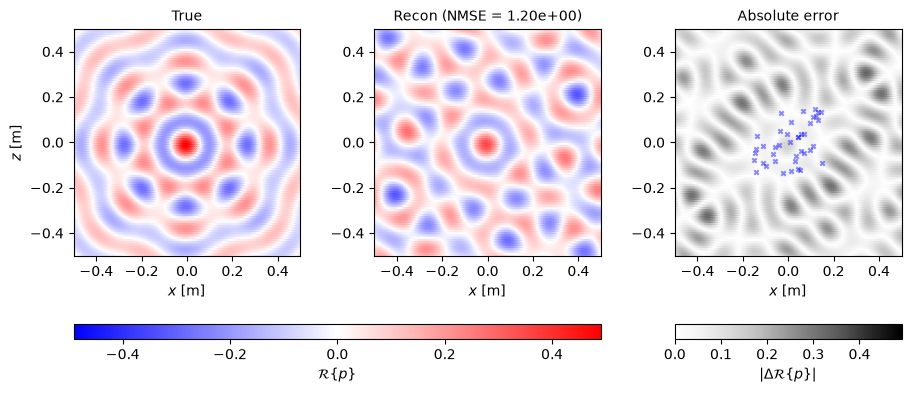

In [87]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon) 

## Conclusões

Neste notebook, exploramos a reconstrução de um campo sonoro bidimensional utilizando a expansão em ondas planas e métodos de solução de problemas inversos com regularização, incluindo a reconstrução esparsa.

As principais conclusões são:

1. **A regularização é essencial para problemas inversos mal postos.** Quando a matriz de sensibilidade representa um sistema subdeterminado ou é mal condicionada, uma solução direta por mínimos quadrados pode ser instável ou não única. A regularização introduz hipóteses adicionais que ajudam a selecionar soluções fisicamente significativas.

2. **A escolha da regularização reflete o conhecimento prévio sobre o campo sonoro.** A regularização de Tikhonov penaliza o quadrado da norma euclidiana dos coeficientes e geralmente produz soluções distribuídas. Em contrapartida, a regularização $\ell_1$ promove soluções esparsas e é particularmente adequada quando o campo sonoro pode ser representado por um pequeno número de ondas planas dominantes.

3. **O parâmetro de regularização controla o compromisso entre o ajuste aos dados e a esparsidade.** Na regularização de Tikhonov ou na regressão Lasso, valores pequenos de $\lambda$ permitem um ajuste mais próximo às medições, enquanto valores maiores promovem uma maior supressão dos coeficientes. Estratégias como o princípio da discrepância, a curva-L e a validação cruzada podem auxiliar na escolha de um parâmetro adequado, embora nenhuma delas seja universalmente ótima.

4. **A recuperação esparsa depende fortemente da matriz de sensibilidade.** A coerência mútua mede a semelhança entre as respostas das ondas planas candidatas nas posições dos microfones. Uma coerência elevada dificulta a distinção entre diferentes direções de propagação, mesmo quando o número de medições parece suficiente.

5. **As condições teóricas de recuperação são úteis, mas frequentemente conservadoras.** A coerência mútua e a Propriedade da Isometria Restrita (RIP) fornecem condições suficientes para a unicidade e a estabilidade da recuperação esparsa. Entretanto, essas condições podem ser difíceis de satisfazer ou verificar para matrizes de sensibilidade com estrutura física específica. O fato de essas condições não serem satisfeitas não implica necessariamente que a reconstrução falhará.

6. **Um número maior de medições não garante automaticamente uma melhor recuperação esparsa.** A disposição dos microfones, a abertura de medição, a frequência e a discretização angular influenciam o condicionamento e a coerência da matriz de sensibilidade. Um número maior de microfones geralmente é benéfico, mas sua distribuição espacial é igualmente importante.

De maneira geral, a reconstrução esparsa de campos sonoros demonstra como **a modelagem física, o projeto do sistema de medição e a regularização devem ser considerados em conjunto**. Uma recuperação bem-sucedida exige não apenas um algoritmo de otimização adequado, mas também uma matriz de sensibilidade capaz de distinguir as componentes de ondas planas relevantes.
